<H3>PRI 2025/26: first project delivery</H3>

**GROUP 06**
- Catarina Gonçalves, 103989
- Isabel Costa, 106868

In [ ]:
import os
import warnings
warnings.filterwarnings('ignore')
import nltk
nltk.download('punkt_tab')
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
from transformers import pipeline
import sys
sys.path.append(os.path.abspath('../src'))
from indexing import indexing
from summarization import summarization, varying_lambda_plot
from keyword_extraction import keyword_extraction
from evaluation_part1 import build_extractive_r_set, evaluation
from EDA_part1 import analyze_sentence_distribution, analyze_noun_phrase_complexity
from question_1 import evaluate_keyword_agreement

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3590.60it/s]
BertModel LOAD REPORT from: BAAI/bge-small-en-v1.5
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3504.41it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
def load_bbc_dataset(base_path):
    D = []
    categories = ['business', 'entertainment', 'politics', 'sport', 'tech']
    
    for category in categories:
        folder_path = os.path.join(base_path, category)
        if not os.path.exists(folder_path):
            continue
            
        for filename in sorted(os.listdir(folder_path)):
            if filename.endswith(".txt"):
                file_path = os.path.join(folder_path, filename)
                with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
                    text = f.read().strip()
                    if text:
                        D.append({'doc_id': f"bbc_{category}_{filename.replace('.txt', '')}",
                                  'text': text,
                                  'category': category})
    print(f"Loaded {len(D)} documents from the BBC dataset.")
    return D

D = load_bbc_dataset('../data/BBC News Summary/News Articles')
R = load_bbc_dataset('../data/BBC News Summary/Summaries')

Loaded 2225 documents from the BBC dataset.
Loaded 2225 documents from the BBC dataset.


<H3>Part 0: exploratory data analysis</H3>

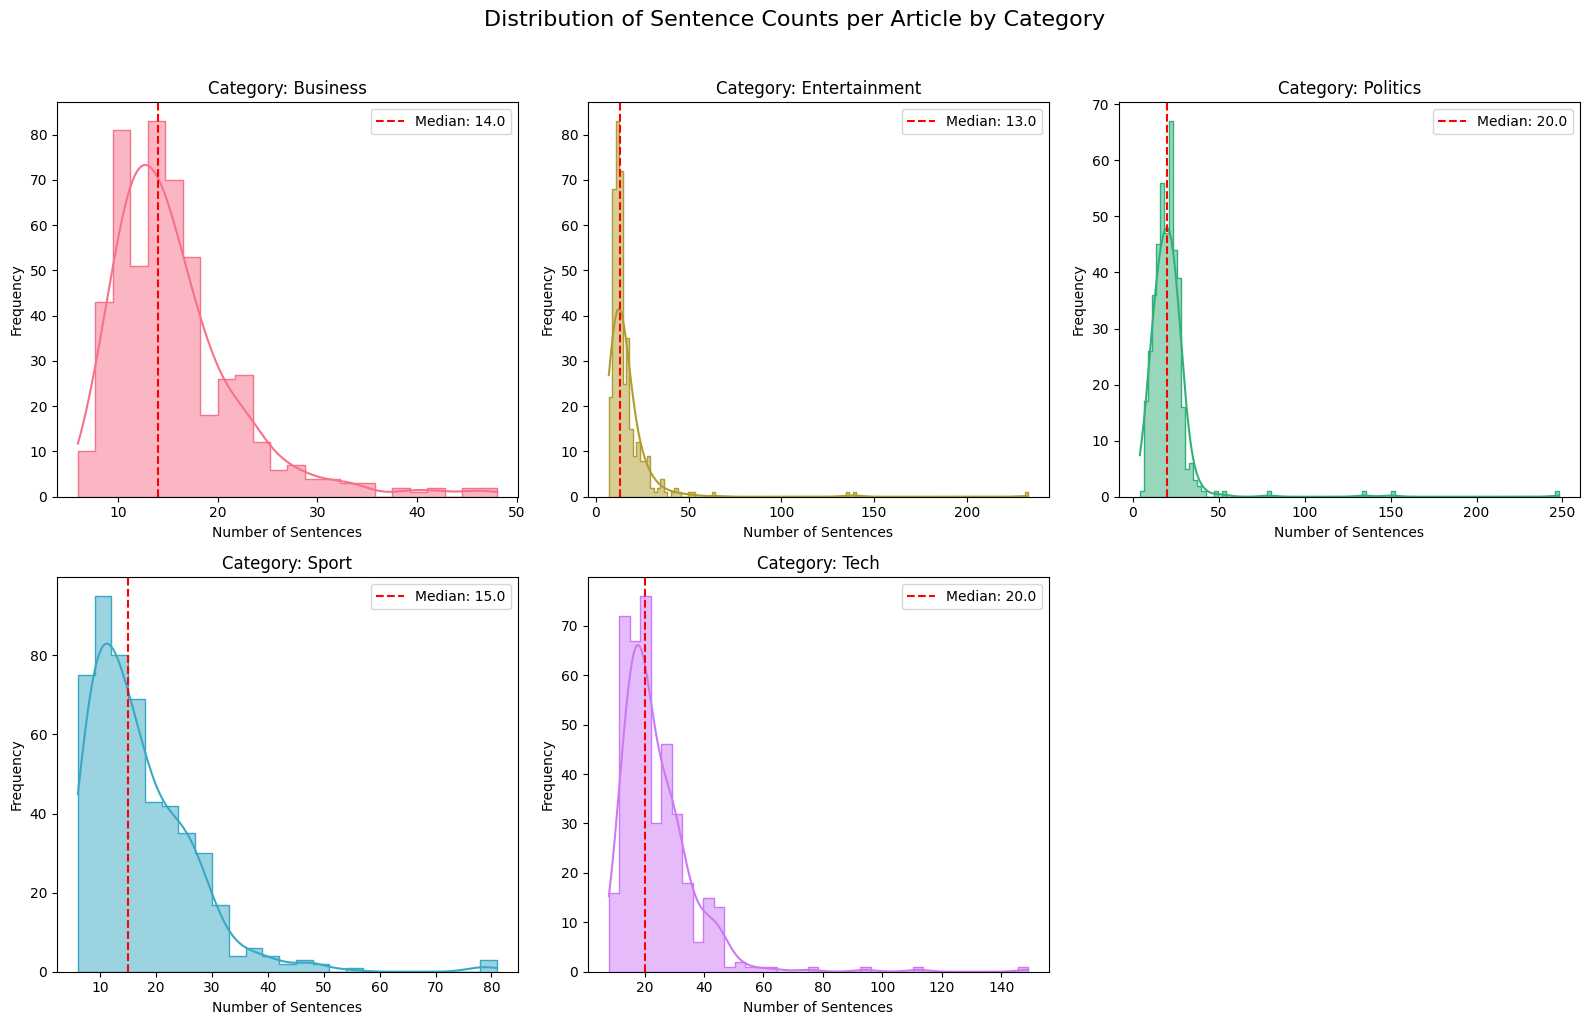

--- Statistics per Category ---
               median       mean        std
category                                   
business         14.0  15.678431   6.497886
entertainment    13.0  16.352332  15.971247
politics         20.0  20.923261  15.800556
sport            15.0  17.090020   9.688872
tech             20.0  24.074813  12.963772

--- Recommended p values (Unsupervised) ---
{'business': 3, 'entertainment': 3, 'politics': 4, 'sport': 3, 'tech': 4}


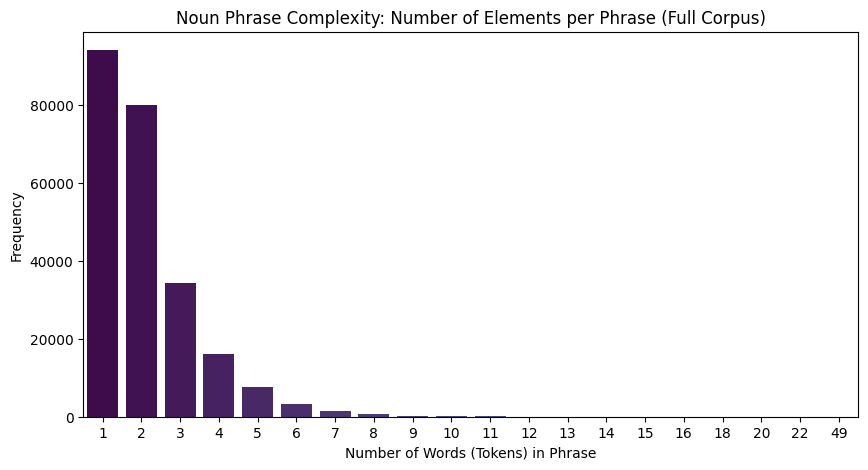

--- Percentage Distribution of Noun Phrase Lengths ---
elements
1     39.537021
2     33.657877
3     14.395907
4      6.779753
5      3.188226
6      1.329931
7      0.616914
8      0.267329
9      0.122963
10     0.056236
11     0.029797
12     0.007554
13     0.002938
14     0.001679
15     0.002518
16     0.001679
18     0.000420
20     0.000420
22     0.000420
49     0.000420
Name: proportion, dtype: float64


In [4]:
# Determining the Optimal Summary Length, p, per Category
p_config, stats = analyze_sentence_distribution(D)
print("--- Statistics per Category ---")
print(stats)
print("\n--- Recommended p values (Unsupervised) ---")
print(p_config)


# Determine the dimension of noun-phrases
np_stats = analyze_noun_phrase_complexity(D)
print("--- Percentage Distribution of Noun Phrase Lengths ---")
print(np_stats)

<H3>Part I: demo of facilities</H3>

A) **Indexing** (preprocessing and indexing options)

In [4]:
args_doc = {'level': 'sentence', 
            'encoder_models': ['BAAI/bge-small-en-v1.5', 'sentence-transformers/all-MiniLM-L6-v2']}

print("Initializing hybrid indexing process (Lexical TF-IDF + Semantic LLM)...")

I, time_taken, memory_size_mb = indexing(D, args_doc)

print("-" * 50)
print("INDEXING COMPLETE")
print("-" * 50)
print(f"Total time taken: {time_taken:.2f} seconds")
print(f"Total memory footprint: {memory_size_mb:.2f} MB")
print(f"Number of items indexed: {len(I['ids'])}")

Initializing hybrid indexing process (Lexical TF-IDF + Semantic LLM)...
Building Lexical Index (TF-IDF) for 41420 items...
Building Semantic Index using LLM: BAAI/bge-small-en-v1.5...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3169.47it/s]
BertModel LOAD REPORT from: BAAI/bge-small-en-v1.5
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Batches: 100%|██████████| 1295/1295 [00:22<00:00, 57.61it/s] 


Building Semantic Index using LLM: sentence-transformers/all-MiniLM-L6-v2...


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3149.77it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Batches: 100%|██████████| 1295/1295 [00:13<00:00, 98.61it/s] 


Indexing Complete! Level: sentence | Time: 281.87s | Size: 121.35 MB
--------------------------------------------------
INDEXING COMPLETE
--------------------------------------------------
Total time taken: 281.87 seconds
Total memory footprint: 121.35 MB
Number of items indexed: 41420


In [6]:
# Visualize the indexes for the first sentence for the frist doc of the business category

# Lexical Index (TF-IDF)
vectorizer = I['lexical']['vectorizer']
matrix = I['lexical']['matrix']
feature_names = vectorizer.get_feature_names_out()

print("\nLexical Index (TF-IDF) Details:")
print(f"\nTotal Vocabulary Size: {len(feature_names)} unique terms")
print(f"TF-IDF Matrix Shape: {matrix.shape}")

# Look at the actual TF-IDF scores for the very first sentence
print(f"Sample TF-IDF scores for '{I['ids'][0]}':")
first_row = matrix[0]
nonzero_indices = first_row.nonzero()[1] # Find columns where the score isn't zero

# Print the first 5 words found in the sentence and their exact TF-IDF weights
for idx in nonzero_indices[:5]:
    print(f"  - '{feature_names[idx]}': {first_row[0, idx]:.4f}")


# Semantic Index (LLM Embeddings)
print("\nSemantic Index (LLM Embeddings) Details:")
for model_name, embeddings in I['semantic'].items():
    print(f"\nModel: {model_name} | Shape: {embeddings.shape}")
    sample_vector = embeddings[0, :5]
    print(f"Sample Vector Data (first 5 dimensions of '{I['ids'][0]}'):")
    print(f"  - {sample_vector}")


Lexical Index (TF-IDF) Details:

Total Vocabulary Size: 49338 unique terms
TF-IDF Matrix Shape: (41420, 49338)
Sample TF-IDF scores for 'bbc_business_001_sent_0':
  - 'ad_sale': 0.3679
  - 'month': 0.1710
  - 'december': 0.2023
  - 'boost': 0.2149
  - 'time': 0.1528

Semantic Index (LLM Embeddings) Details:

Model: BAAI/bge-small-en-v1.5 | Shape: (41420, 384)
Sample Vector Data (first 5 dimensions of 'bbc_business_001_sent_0'):
  - [ 0.00845436  0.01273891  0.03685027 -0.02156246  0.06798306]

Model: sentence-transformers/all-MiniLM-L6-v2 | Shape: (41420, 384)
Sample Vector Data (first 5 dimensions of 'bbc_business_001_sent_0'):
  - [-0.00814034 -0.01538559 -0.01918245 -0.03079472  0.04750923]


B) **Extractive summarization**

*B.1 Summarization baseline solution: results for a given document*

In [7]:
# Grab a random document to test
test_doc = D[0] 
all_sentences = nltk.sent_tokenize(test_doc['text'])
print(f"Testing Baseline Summarizer on Doc: {test_doc['doc_id']}\n")

# Set args for the baseline mode
baseline_args = {'summary_mode': 'baseline'}
# Run the summarizer
baseline_output = summarization(test_doc, p=5, l=None, I=I, args=baseline_args)

print("Extracted Baseline Sentences:")
for pos, score in baseline_output:
    print(f"Position {pos}: {all_sentences[pos]}")

Testing Baseline Summarizer on Doc: bbc_business_001

Extracted Baseline Sentences:
Position 0: Ad sales boost Time Warner profit

Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier.
Position 1: The firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and higher advert sales.
Position 2: TimeWarner said fourth quarter sales rose 2% to $11.1bn from $10.9bn.
Position 3: Its profits were buoyed by one-off gains which offset a profit dip at Warner Bros, and less users for AOL.
Position 4: Time Warner said on Friday that it now owns 8% of search-engine Google.


*B.2 IR models (TF-IDF, BM25, lightweight encoder LLMs)*

In [8]:
test_doc = D[0] 
all_sentences = nltk.sent_tokenize(test_doc['text'])

print(f"Testing Extractive Summaries on Document: {test_doc['doc_id']}\n")

# TEST 1: lexical, sparce matrix (BM25)
print("=== LEXICAL EXTRACTIVE INDEX (BM25) ===")
lexical_args = {'summary_mode': 'extractive', 'model_family': 'lexical'}
lexical_raw = summarization(test_doc, p=3, l=None, I=I, args=lexical_args)

print("Raw Pairs (Position, Score):", lexical_raw)

# Map positions to text
lexical_text = " ".join([all_sentences[pos] for pos, score in lexical_raw])
print("Readable Summary:")
print(lexical_text)

# TEST 2: semantic, dense matrix (Cosine Similarity)
print("=== SEMANTIC EXTRACTIVE INDEX (Embeddings) ===")
semantic_args = {'summary_mode': 'extractive', 'model_family': 'semantic'}
semantic_raw = summarization(test_doc, p=3, l=None, I=I, args=semantic_args)

print("Raw Pairs (Position, Score):", semantic_raw)

# Map positions to text
semantic_text = " ".join([all_sentences[pos] for pos, score in semantic_raw])
print("Readable Summary:")
print(semantic_text)

Testing Extractive Summaries on Document: bbc_business_001

=== LEXICAL EXTRACTIVE INDEX (BM25) ===
Raw Pairs (Position, Score): [(8, np.float64(100.11777266588996)), (11, np.float64(104.36532363941402)), (13, np.float64(99.13120738219246))]
Readable Summary:
It hopes to increase subscribers by offering the online service free to TimeWarner internet customers and will try to sign up AOL's existing customers for high-speed broadband. But its film division saw profits slump 27% to $284m, helped by box-office flops Alexander and Catwoman, a sharp contrast to year-earlier, when the third and final film in the Lord of the Rings trilogy boosted results. "Our financial performance was strong, meeting or exceeding all of our full-year objectives and greatly enhancing our flexibility," chairman and chief executive Richard Parsons said.
=== SEMANTIC EXTRACTIVE INDEX (Embeddings) ===
Raw Pairs (Position, Score): [(0, 0.807278573513031), (7, 0.7930611968040466), (12, 0.7924334406852722)]
Readable 

*B.3 Maximal Marginal Relevance*

In [9]:
# Fixing lambda = 0.5 for MMR
standard_redundancy_total = 0.0
mmr_redundancy_total = 0.0

docs_to_test = D

for doc in docs_to_test:
    all_sentences = nltk.sent_tokenize(doc['text'])
    
    # Lexical Summarization
    std_args = {'summary_mode': 'extractive', 'model_family': 'lexical'}
    std_output = summarization(doc, p=5, l=None, I=I, args=std_args)
    std_texts = [all_sentences[pos] for pos, score in std_output]
    
    if len(std_texts) > 1:
        vectorizer = TfidfVectorizer()
        tfidf_matrix = vectorizer.fit_transform(std_texts)
        sim_matrix = cosine_similarity(tfidf_matrix)
        upper_tri = sim_matrix[np.triu_indices(len(std_texts), k=1)]
        standard_redundancy_total += np.mean(upper_tri)

    # MMR Summarization (Lambda = 0.5) 
    mmr_args = {'summary_mode': 'mmr', 'model_family': 'lexical', 'mmr_lambda': 0.5}
    mmr_output = summarization(doc, p=5, l=None, I=I, args=mmr_args)
    mmr_texts = [all_sentences[pos] for pos, score in mmr_output]
    
    if len(mmr_texts) > 1:
        vectorizer = TfidfVectorizer()
        tfidf_matrix = vectorizer.fit_transform(mmr_texts)
        sim_matrix = cosine_similarity(tfidf_matrix)
        upper_tri = sim_matrix[np.triu_indices(len(mmr_texts), k=1)]
        mmr_redundancy_total += np.mean(upper_tri)

# Calculate Averages
num_docs = len(docs_to_test)
avg_std_redundancy = standard_redundancy_total / num_docs
avg_mmr_redundancy = mmr_redundancy_total / num_docs

print(f"RESULTS ACROSS {num_docs} DOCUMENTS:")
print(f"Standard Summarizer Average Redundancy: {avg_std_redundancy:.4f}")
print(f"MMR (λ=0.5) Average Redundancy: {avg_mmr_redundancy:.4f}")
print(f"Improvement: MMR reduced redundancy by {(avg_std_redundancy - avg_mmr_redundancy):.4f}")

RESULTS ACROSS 2225 DOCUMENTS:
Standard Summarizer Average Redundancy: 0.1081
MMR (λ=0.5) Average Redundancy: 0.0884
Improvement: MMR reduced redundancy by 0.0197


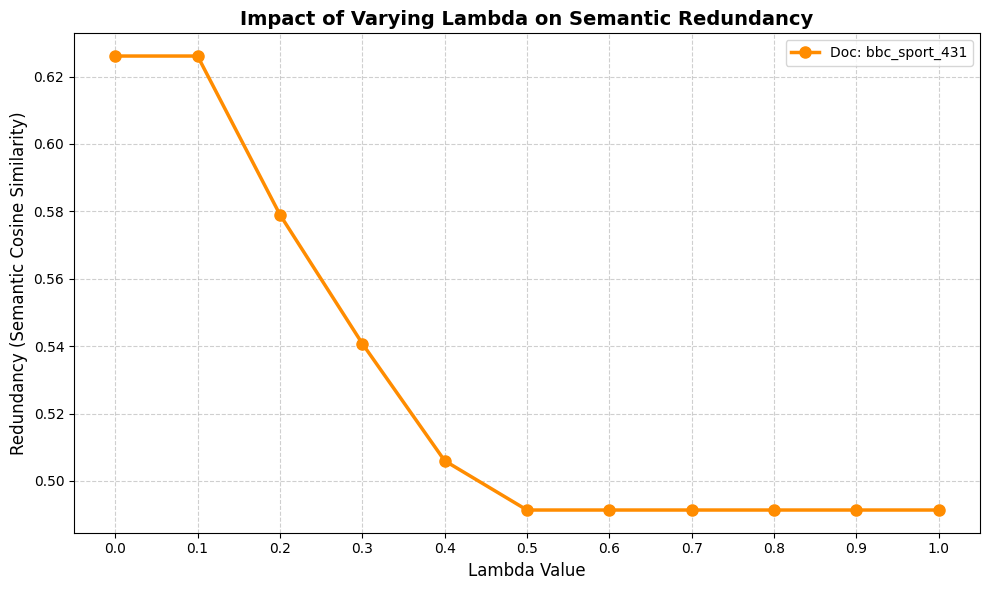

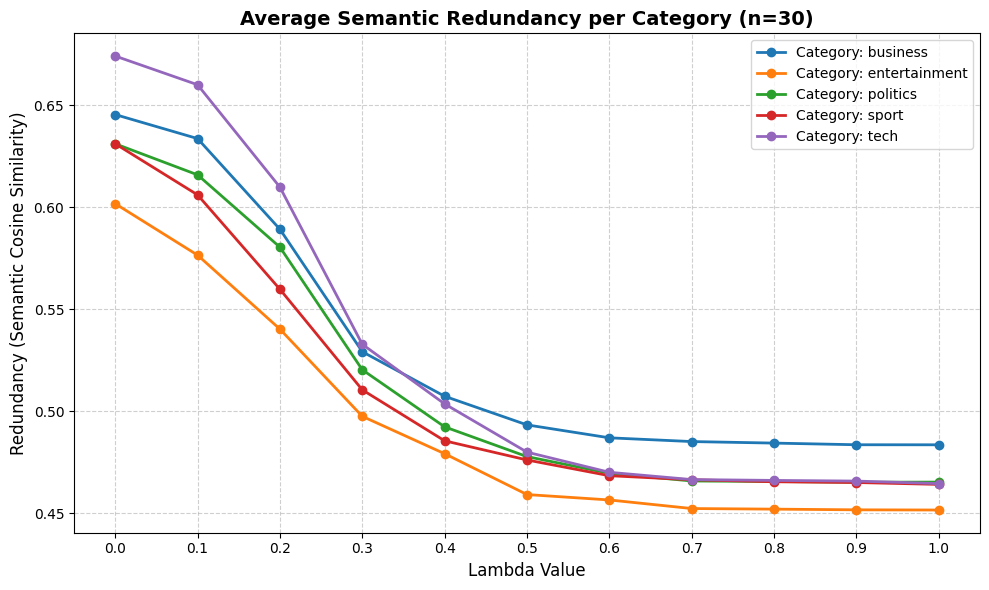

In [10]:
# Plot the varying lambda on a sibgle document
varying_lambda_plot(D, I, mode='single')

# Plot the varying lambda across categories
varying_lambda_plot(D, I, mode='category', sample_size=30)


C) **Abstractive summarization**

*C.1 Prompting decoder LLMs*

In [6]:
# Load the model
print("Loading TinyLlama...")
tiny_llama_pipe = pipeline("text-generation", model="TinyLlama/TinyLlama-1.1B-Chat-v1.0")

test_doc = D[0]
print(f"\nTesting Abstractive Summarizer on Doc: {test_doc['doc_id']}\n")

# Arguments
abstractive_args = {'summary_mode': 'abstractive',
                    'summary_generator': tiny_llama_pipe,  
                    'prompt_type': 'prompt_1',
                    'max_summary_length': 100}

# Generate the summary
generated_text = summarization(test_doc, p=None, l=None, I=I, args=abstractive_args)

print("Generated Summary")
print(generated_text)

print("Loading DistilGPT2...")
distilgpt2_pipe = pipeline("text-generation", model="distilgpt2")

test_doc = D[0]
print(f"\nTesting Abstractive Summarizer on Doc: {test_doc['doc_id']} with DistilGPT2\n")

# Arguments for the second model
abstractive_args_2 = {'summary_mode': 'abstractive',
                      'summary_generator': distilgpt2_pipe, 
                      'decoder_llm_summary': 'distilgpt2',
                      'prompt_type': 'prompt_2', 
                      'max_summary_length': 100}

# Generate the summary
generated_text_2 = summarization(test_doc, p=None, l=None, I=I, args=abstractive_args_2)

print("Generated Summary (DistilGPT2):")
print(generated_text_2)

Loading TinyLlama...


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 8822.17it/s]
Passing `generation_config` together with generation-related arguments=({'temperature', 'num_return_sequences', 'max_new_tokens', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=100) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Testing Abstractive Summarizer on Doc: bbc_business_001

Generated Summary
The article discusses the financial performance of US media giant TimeWarner, which includes a 76% increase in quarterly profits of $1.13bn (£600m) for the three months to December 2005. The company's profits were boosted by higher advertising sales and higher internet revenues, with sales of high-speed internet connections and higher advertising revenues contributing to the increase. The article also notes that
Loading DistilGPT2...


Loading weights: 100%|██████████| 76/76 [00:00<00:00, 1024.69it/s]
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Both `max_new_tokens` (=100) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Testing Abstractive Summarizer on Doc: bbc_business_001 with DistilGPT2

Generated Summary (DistilGPT2):
The company has been a major player in the internet industry since its inception in 2007.
Time Warner has been a major player in the internet industry since its inception in 2007.
The company has been a major player in the internet industry since its inception in 2007.
The company has been a major player in the internet industry since its inception in 2007.
The company has been a major player in the internet industry since its inception in 2007.
The company has been a major player in the internet


*C.2 Reciprocal rank funsion*

In [12]:
test_doc = D[1000] 
all_sentences = nltk.sent_tokenize(test_doc['text'])
p_sentences = 4  # Number of sentences we want to extract

print(f"Comparing IR Models for Document: {test_doc['doc_id']}\n")

# Lexical Summary
lexical_args = {'summary_mode': 'extractive', 'model_family': 'lexical'}
lexical_output = summarization(test_doc, p=p_sentences, l=None, I=I, args=lexical_args)

print("Lexical Summary")
for pos, score in lexical_output:
    print(f"[{pos}] (Score: {score:.4f}): {all_sentences[pos]}")
print("\n")

# Semantic Summary 
semantic_args = {'summary_mode': 'extractive', 'model_family': 'semantic'}
semantic_output = summarization(test_doc, p=p_sentences, l=None, I=I, args=semantic_args)

print("Semantic Summary")
for pos, score in semantic_output:
    print(f"[{pos}] (Score: {score:.4f}): {all_sentences[pos]}")
print("\n")

# Reciprocal Rank Fusion 
rrf_args = {'summary_mode': 'rrf', 'rrf_mu': 5.0}
rrf_output = summarization(test_doc, p=p_sentences, l=None, I=I, args=rrf_args)

print("RRF Summary")
for pos, score in rrf_output:
    print(f"[{pos}] (Score: {score:.4f}): {all_sentences[pos]}")
print("\n")

Comparing IR Models for Document: bbc_politics_105

Lexical Summary
[4] (Score: 97.5178): "The threat is most likely to come from those people associated with an extreme form of Islam, or who are falsely hiding behind Islam," the Salford MP told the Commons home affairs committee.
[10] (Score: 86.2009): IHRC chairman Massoud Shadjareh accused Ms Blears of "playing an Islamophobia card" in the run-up to a general election.
[18] (Score: 93.3595): Statistics showed that of the 17 people found guilty of terrorist acts in the UK since the 11 September attacks, only four of the 12 whose ethnic backgrounds were known were Muslim, he added Figures published last week showed that people from ethnic minorities were increasingly likely to be targeted by police stop and search tactics.
[23] (Score: 96.6860): Last July, the police were accused of Islamophobia by Muslim groups after stop and search figures showed the numbers of Asians targeted had risen by 300% since the introduction of anti-terror 

D) **Keyword extraction**

In [ ]:
import gc
import torch

indexing_args = {'level': 'document', 
                 'encoder_models': ['BAAI/bge-small-en-v1.5']}

I, indexing_time, memory_size_mb = indexing(D, indexing_args)
print(f"Success! Index built in {indexing_time:.2f} seconds.\n")


args_extractive = {"keyword_mode": "extractive"}

args_abstractive = {"keyword_mode": "abstractive",
                    "decoder_llm_keywords": ["TinyLlama/TinyLlama-1.1B-Chat-v1.0", 
                                             "Qwen/Qwen2.5-0.5B-Instruct" ]}

for d in D[:1]:  
    doc_id = d['doc_id']
    
    print(f"\n--- Extracting Keywords for Document: {doc_id} ---")

    keywords_tfidf = keyword_extraction(d, 10, I, args_extractive)
    print(f"TF-IDF Found: {keywords_tfidf}")

    # Extract 10 keywords for the generative models
    all_abstractive_keywords = keyword_extraction(d, 10, I, args_abstractive)
    
    # Print the results
    print(f"TinyLlama Found: {all_abstractive_keywords['TinyLlama/TinyLlama-1.1B-Chat-v1.0']}")
    print(f"Qwen Found: {all_abstractive_keywords['Qwen/Qwen2.5-0.5B-Instruct']}")

    gc.collect()
    torch.cuda.empty_cache()
    

Building Lexical Index (TF-IDF) for 2225 items...
Building Semantic Index using LLM: BAAI/bge-small-en-v1.5...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8293.34it/s]
BertModel LOAD REPORT from: BAAI/bge-small-en-v1.5
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Batches: 100%|██████████| 70/70 [00:10<00:00,  6.47it/s]


Indexing Complete! Level: document | Time: 130.22s | Size: 3.26 MB
Success! Index built in 130.22 seconds.


--- Extracting Keywords for Document: bbc_business_001 ---
TF-IDF Found: ['timewarner', 'profit', 'aol', 'aol europe', 'stake', 'warner', 'restate', 'fourth', 'sale', 'sec']
  -> Running internal extraction with: TinyLlama/TinyLlama-1.1B-Chat-v1.0


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 611.95it/s]
Passing `generation_config` together with generation-related arguments=({'num_return_sequences', 'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=50) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  -> Running internal extraction with: Qwen/Qwen2.5-0.5B-Instruct


Loading weights: 100%|██████████| 290/290 [00:00<00:00, 1566.48it/s]
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=75) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


... (3,319 outputs left out)

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 1707.44it/s]
Both `max_new_tokens` (=75) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


TinyLlama Found: ['british phonographic industry', 'uk music industry', 'music industry', 'cd albums', 'albums', 'uk', 'biggest music buyer', "world's biggest music buyer", 'sales', 'total yearly sales']
Qwen Found: ['uk', 'music', 'buyers', 'bpi', 'figures', 'decline', 'dvd', 'music', 'volumes', 'uk']

--- Extracting Keywords for Document: bbc_entertainment_322 ---
TF-IDF Found: ['pixy', 'foo fighter', 'maiden', 'read', 'iron', 'headline', 'festival', 'iron maiden', 'reading', 'leed']
  -> Running internal extraction with: TinyLlama/TinyLlama-1.1B-Chat-v1.0


Loading weights:  61%|██████    | 122/201 [00:00<00:00, 543.31it/s]


KeyboardInterrupt: 

E) **Evaluation**

In [ ]:
import gc
import torch

# Force Python's garbage collector to clean up
gc.collect()

# Force PyTorch to empty its cache
torch.cuda.empty_cache()

print("GPU Memory cleared!")

GPU Memory cleared!


Total Documents to Evaluate: 2225

Building Extractive Ground Truths with Category-Specific p-values...
  - Building R_set for Business (p=3, docs=510)
Building R_set (Ground Truth IDs) using Semantic Matching...


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 12866.35it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


R_set successfully built!
  - Building R_set for Entertainment (p=3, docs=386)
Building R_set (Ground Truth IDs) using Semantic Matching...


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8998.03it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


R_set successfully built!
  - Building R_set for Politics (p=4, docs=417)
Building R_set (Ground Truth IDs) using Semantic Matching...


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 11175.26it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (3 outputs left out)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 10232.92it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


R_set successfully built!

Pre-loading Abstractive LLM Pipeline...


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 8350.06it/s]



RUNNING PIPELINE FOR: Baseline Mode


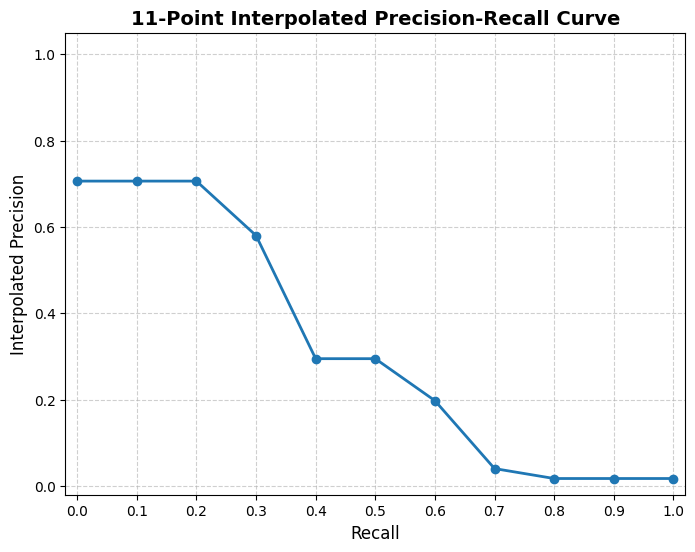


--- EXTRACTIVE RESULTS ---
F-Beta: 0.3708 | AP: 0.3125

--- CATEGORY BREAKDOWN (F-Beta) ---
- Business: 0.3980
- Entertainment: 0.3826
- Politics: 0.3429
- Sport: 0.3881
- Tech: 0.3317
Loading independent evaluator LLM: all-mpnet-base-v2...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7694.20it/s]
MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



--- ABSTRACTIVE RESULTS ---
ROUGE-1: 0.4759 | ROUGE-2: 0.3698
ROUGE-L: 0.3543 | Sem-Sim: 0.8171

RUNNING PIPELINE FOR: Lexical Model (BM25)


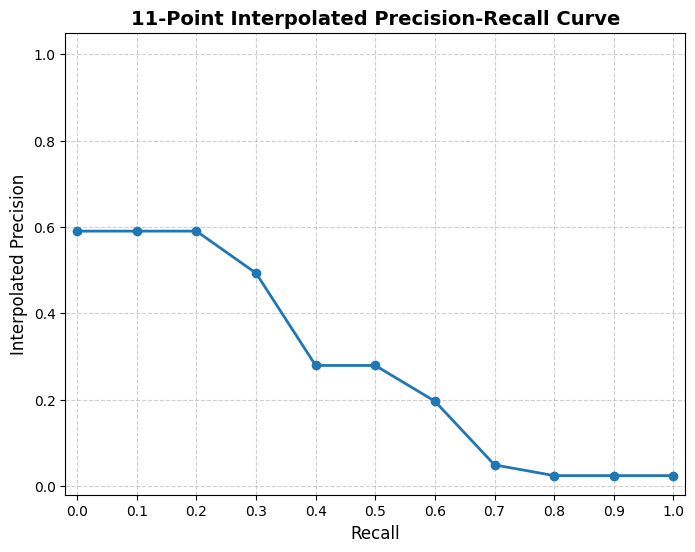


--- EXTRACTIVE RESULTS ---
F-Beta: 0.3663 | AP: 0.2729

--- CATEGORY BREAKDOWN (F-Beta) ---
- Business: 0.3477
- Entertainment: 0.3679
- Politics: 0.3507
- Sport: 0.4299
- Tech: 0.3236
Loading independent evaluator LLM: all-mpnet-base-v2...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 10129.20it/s]
MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



--- ABSTRACTIVE RESULTS ---
ROUGE-1: 0.4975 | ROUGE-2: 0.3785
ROUGE-L: 0.3669 | Sem-Sim: 0.8124

RUNNING PIPELINE FOR: Semantic (BAAI)


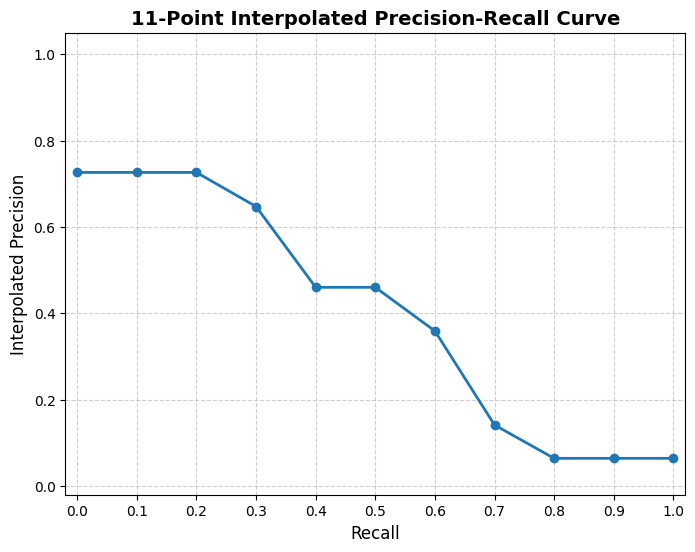


--- EXTRACTIVE RESULTS ---
F-Beta: 0.4834 | AP: 0.3940

--- CATEGORY BREAKDOWN (F-Beta) ---
- Business: 0.4954
- Entertainment: 0.5069
- Politics: 0.5060
- Sport: 0.4710
- Tech: 0.4377
Loading independent evaluator LLM: all-mpnet-base-v2...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 9202.40it/s]
MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



--- ABSTRACTIVE RESULTS ---
ROUGE-1: 0.5379 | ROUGE-2: 0.4554
ROUGE-L: 0.3980 | Sem-Sim: 0.8347

RUNNING PIPELINE FOR: Semantic (MiniLM)


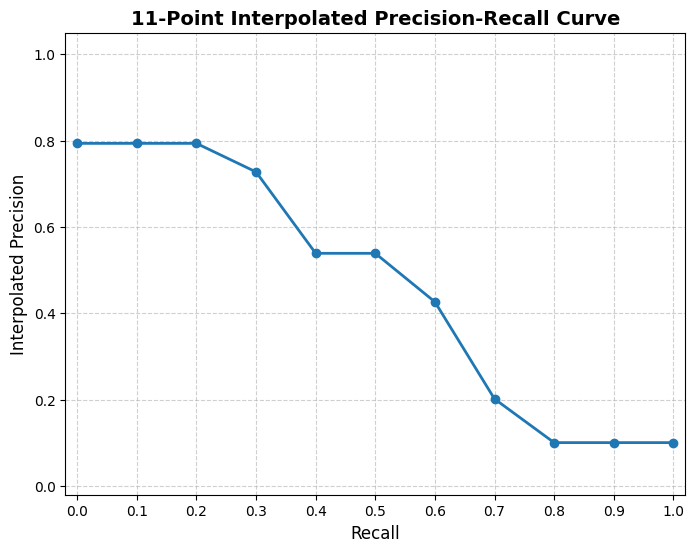


--- EXTRACTIVE RESULTS ---
F-Beta: 0.5321 | AP: 0.4570

--- CATEGORY BREAKDOWN (F-Beta) ---
- Business: 0.5745
- Entertainment: 0.5181
- Politics: 0.5564
- Sport: 0.4684
- Tech: 0.5474
Loading independent evaluator LLM: all-mpnet-base-v2...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8777.09it/s]
MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



--- ABSTRACTIVE RESULTS ---
ROUGE-1: 0.5526 | ROUGE-2: 0.4755
ROUGE-L: 0.4111 | Sem-Sim: 0.8362

RUNNING PIPELINE FOR: MMR (Semantic, Lambda = 0.2)


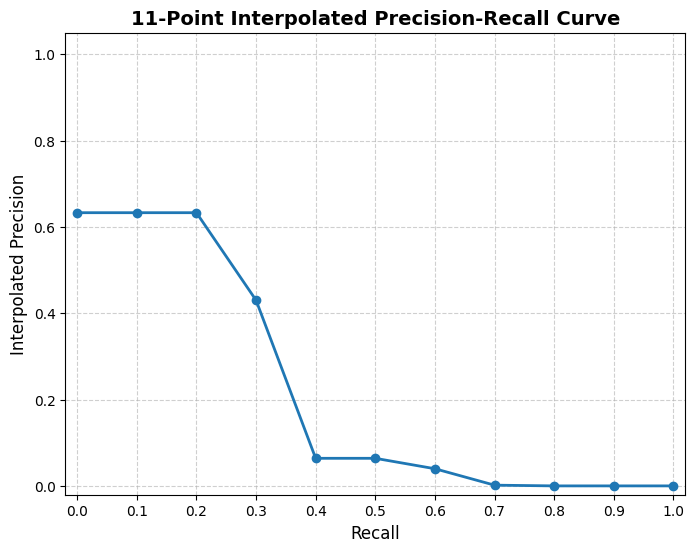


--- EXTRACTIVE RESULTS ---
F-Beta: 0.2422 | AP: 0.2116

--- CATEGORY BREAKDOWN (F-Beta) ---
- Business: 0.2608
- Entertainment: 0.2668
- Politics: 0.2236
- Sport: 0.2642
- Tech: 0.1864
Loading independent evaluator LLM: all-mpnet-base-v2...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7905.91it/s]
MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



--- ABSTRACTIVE RESULTS ---
ROUGE-1: 0.4180 | ROUGE-2: 0.2944
ROUGE-L: 0.3105 | Sem-Sim: 0.7938

RUNNING PIPELINE FOR: MMR (Semantic, Lambda = 0.5)


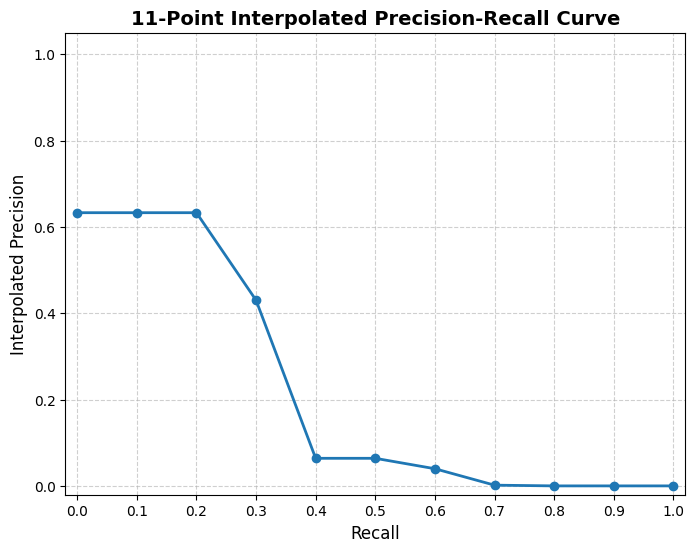


--- EXTRACTIVE RESULTS ---
F-Beta: 0.2422 | AP: 0.2116

--- CATEGORY BREAKDOWN (F-Beta) ---
- Business: 0.2608
- Entertainment: 0.2668
- Politics: 0.2236
- Sport: 0.2642
- Tech: 0.1864
Loading independent evaluator LLM: all-mpnet-base-v2...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7815.08it/s]
MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



--- ABSTRACTIVE RESULTS ---
ROUGE-1: 0.4180 | ROUGE-2: 0.2944
ROUGE-L: 0.3105 | Sem-Sim: 0.7938

RUNNING PIPELINE FOR: MMR (Semantic, Lambda = 0.8)


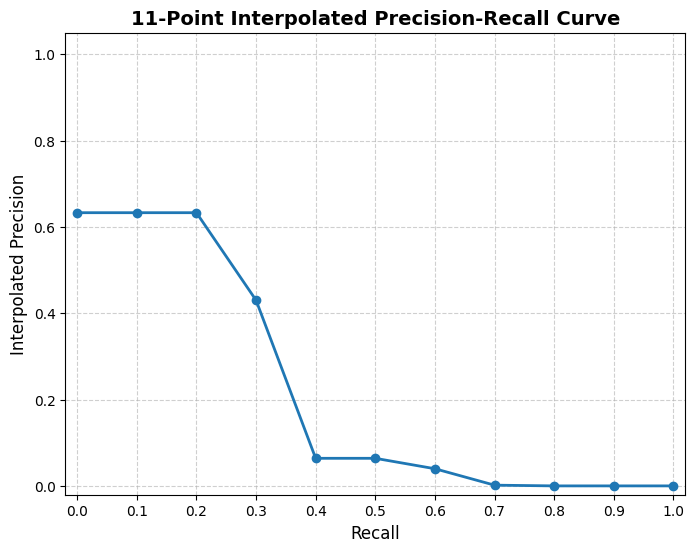


--- EXTRACTIVE RESULTS ---
F-Beta: 0.2422 | AP: 0.2116

--- CATEGORY BREAKDOWN (F-Beta) ---
- Business: 0.2608
- Entertainment: 0.2668
- Politics: 0.2236
- Sport: 0.2642
- Tech: 0.1864
Loading independent evaluator LLM: all-mpnet-base-v2...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 9526.53it/s]
MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Passing `generation_config` together with generation-related arguments=({'do_sample', 'max_new_tokens', 'temperature', 'num_return_sequences'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=100) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



--- ABSTRACTIVE RESULTS ---
ROUGE-1: 0.4180 | ROUGE-2: 0.2944
ROUGE-L: 0.3105 | Sem-Sim: 0.7938

RUNNING PIPELINE FOR: Abstractive (TinyLlama)


Both `max_new_tokens` (=100) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=100) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=100) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=100) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

Loading independent evaluator LLM: all-mpnet-base-v2...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7140.31it/s]
MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



--- ABSTRACTIVE RESULTS ---
ROUGE-1: 0.4195 | ROUGE-2: 0.2474
ROUGE-L: 0.2726 | Sem-Sim: 0.8042

RUNNING PIPELINE FOR: RRF Model (Fusion)


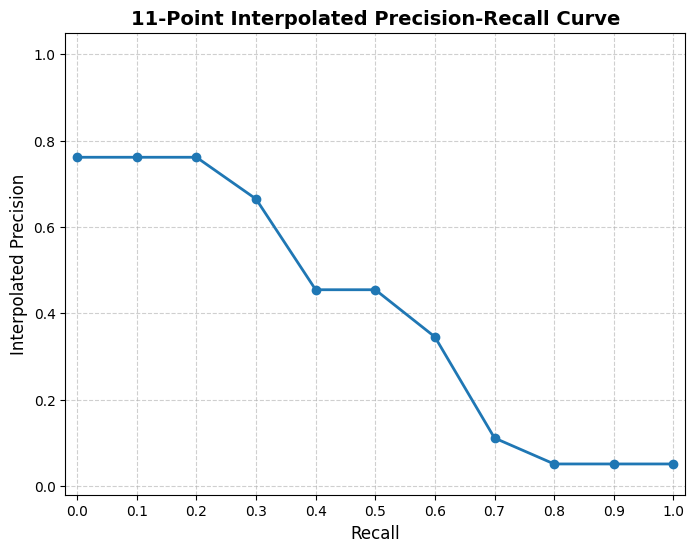


--- EXTRACTIVE RESULTS ---
F-Beta: 0.4752 | AP: 0.3965

--- CATEGORY BREAKDOWN (F-Beta) ---
- Business: 0.4797
- Entertainment: 0.4931
- Politics: 0.4646
- Sport: 0.5023
- Tech: 0.4289
Loading independent evaluator LLM: all-mpnet-base-v2...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8179.00it/s]
MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



--- ABSTRACTIVE RESULTS ---
ROUGE-1: 0.5401 | ROUGE-2: 0.4445
ROUGE-L: 0.3995 | Sem-Sim: 0.8380


In [4]:
import gc
import torch

# !! LLM-aided code block
experiment_D = D 
experiment_R = [r for r in R if r['doc_id'] in [d['doc_id'] for d in experiment_D]]

print(f"Total Documents to Evaluate: {len(experiment_D)}")

# Helper to print category breakdowns
def scores_per_category(doc_scores, doc_cats, metric='f_beta'):
    categories = ['business', 'entertainment', 'politics', 'sport', 'tech']
    for cat in categories:
        scores = [metrics[metric] for doc_id, metrics in doc_scores.items() if doc_cats.get(doc_id) == cat]
        if scores:
            avg_score = sum(scores) / len(scores)
            print(f"- {cat.capitalize()}: {avg_score:.4f}")

# Build Ground Truths Based on EDA (p=4 vs p=3)
print("\nBuilding Extractive Ground Truths with Category-Specific p-values...")
R_set_extractive = {}
categories_to_process = ['business', 'entertainment', 'politics', 'sport', 'tech']

for cat in categories_to_process:
    cat_D = [d for d in experiment_D if d['category'] == cat]
    cat_R = [r for r in experiment_R if r['doc_id'] in [d['doc_id'] for d in cat_D]]
    p_val = 4 if cat in ['politics', 'tech'] else 3
    
    if cat_D:
        print(f"  - Building R_set for {cat.capitalize()} (p={p_val}, docs={len(cat_D)})")
        cat_R_set = build_extractive_r_set(cat_D, cat_R, p_sentences=p_val)
        R_set_extractive.update(cat_R_set)

R_set_abstractive = {item['doc_id']: item['text'] for item in experiment_R}
doc_categories = {doc['doc_id']: doc['category'] for doc in experiment_D}

print("\nPre-loading Abstractive LLM Pipeline...")
from transformers import pipeline
tinyllama_pipeline = pipeline("text-generation", model="TinyLlama/TinyLlama-1.1B-Chat-v1.0")

# Define the Models using YOUR routing keys
models_to_test = [{'name': 'Baseline Mode', 'lam': None, 'args': {'summary_mode': 'baseline'}},
                  # Question 2: Lexical Model
                  {'name': 'Lexical Model (BM25)', 'lam': None, 'args': {'summary_mode': 'extractive', 'model_family': 'lexical'}},
                  # Question 3: Which LLM Encoder is better? (BAAI vs MiniLM)
                  {'name': 'Semantic (BAAI)', 'lam': None, 'args': {'summary_mode': 'extractive', 'model_family': 'semantic', 'selected_encoder': 'BAAI/bge-small-en-v1.5'}},
                  {'name': 'Semantic (MiniLM)', 'lam': None, 'args': {'summary_mode': 'extractive', 'model_family': 'semantic', 'selected_encoder': 'sentence-transformers/all-MiniLM-L6-v2'}},
                  # Question 4: MMR Lambda Sweep (Notice we use summary_mode: 'mmr' here!)
                  {'name': 'MMR (Semantic, Lambda = 0.2)', 'lam': 0.2, 'args': {'summary_mode': 'mmr', 'model_family': 'semantic', 'selected_encoder': 'BAAI/bge-small-en-v1.5'}},
                  {'name': 'MMR (Semantic, Lambda = 0.5)', 'lam': 0.5, 'args': {'summary_mode': 'mmr', 'model_family': 'semantic', 'selected_encoder': 'BAAI/bge-small-en-v1.5'}},
                  {'name': 'MMR (Semantic, Lambda = 0.8)', 'lam': 0.8, 'args': {'summary_mode': 'mmr', 'model_family': 'semantic', 'selected_encoder': 'BAAI/bge-small-en-v1.5'}},
                  # Question 5: Abstractive (Notice we pass the pre-loaded pipeline!)
                  {'name': 'Abstractive (TinyLlama)', 'lam': None, 'args': {'summary_mode': 'abstractive', 'summary_generator': tinyllama_pipeline, 'prompt_type': 'prompt_1'}},
                  # Question 6: RRF utility
                   {'name': 'RRF Model (Fusion)', 'lam': None, 'args': {'summary_mode': 'rrf', 'rrf_mu': 5.0}}]

final_results = {}

# Run the evaluation loop
for model in models_to_test:
    print(f"\n==================================================")
    print(f"RUNNING PIPELINE FOR: {model['name']}")
    print(f"==================================================")
    
    S_set_ext = {}
    S_set_abs = {}

    for doc in experiment_D:
        doc_id = doc['doc_id']
        cat = doc['category']
        p_val = 4 if cat in ['politics', 'tech'] else 3
        all_sentences = nltk.sent_tokenize(doc['text'])
        
        # Determine if this model returns pairs or raw text
        if model['args']['summary_mode'] == 'abstractive':
            # Abstractive just returns the generated string!
            stitched_text = summarization(doc, p=p_val, l=model['lam'], I=I, args=model['args'])
            S_set_abs[doc_id] = stitched_text
        else:
            # Extractive/MMR/Baseline return ranked pairs
            raw_ranked_pairs = summarization(doc, p=p_val, l=model['lam'], I=I, args=model['args'])
            S_set_ext[doc_id] = raw_ranked_pairs
            
            # Reconstruct string for abstractive evaluation
            stitched_text = " ".join([all_sentences[pos] for pos, score in raw_ranked_pairs])
            S_set_abs[doc_id] = stitched_text
    
    ext_res = None

    # Evaluate
    if model['args']['summary_mode'] != 'abstractive':
        ext_args = {"eval_mode": "extractive", "doc_categories": doc_categories}
        ext_res = evaluation(S_set_ext, R_set_extractive, ext_args)
        print(f"\n--- EXTRACTIVE RESULTS ---")
        print(f"F-Beta: {ext_res['macro_averages']['Macro_F_beta']:.4f} | AP: {ext_res['macro_averages']['Macro_AP']:.4f}")
        print(f"\n--- CATEGORY BREAKDOWN (F-Beta) ---")
        scores_per_category(ext_res['document_scores'], doc_categories, metric='f_beta')

    # Evaluate Abstractive (Runs for ALL models so you can compare Sem-Sim!)
    abs_args = {"eval_mode": "abstractive", "eval_encoder": "all-mpnet-base-v2"}
    abs_res = evaluation(S_set_abs, R_set_abstractive, abs_args)
    
    print(f"\n--- ABSTRACTIVE RESULTS ---")
    print(f"ROUGE-1: {abs_res['macro_averages']['Average_ROUGE-1']:.4f} | ROUGE-2: {abs_res['macro_averages']['Average_ROUGE-2']:.4f}")
    print(f"ROUGE-L: {abs_res['macro_averages']['Average_ROUGE-L']:.4f} | Sem-Sim: {abs_res['macro_averages']['Average_Semantic_Similarity']:.4f}")

    final_results[model['name']] = {'Extractive': ext_res['macro_averages'] if ext_res else None,
                                    'Abstractive': abs_res['macro_averages']}
    
    gc.collect()
    torch.cuda.empty_cache()

In [ ]:
# !! LLM-aided code block
experiment_D = D
experiment_R = [r for r in R if r['doc_id'] in [d['doc_id'] for d in experiment_D]]

print(f"Total Documents to Evaluate: {len(experiment_D)}")

# Build Abstractive Ground Truths
print("\nBuilding Abstractive Ground Truths...")
R_set_abstractive = {item['doc_id']: item['text'] for item in experiment_R}
doc_categories = {doc['doc_id']: doc['category'] for doc in experiment_D}

# Pre-load the SECOND Abstractive LLM Pipeline (DistilGPT2)
from transformers import pipeline
print("\nPre-loading Abstractive LLM Pipeline (distilgpt2)...")
distilgpt2_pipeline = pipeline("text-generation", model="distilgpt2")

# Define ONLY the second abstractive model
models_to_test = [{'name': 'Abstractive (DistilGPT2 - Prompt 2)', 'lam': None, 'args': {'summary_mode': 'abstractive', 
                                                                                        'decoder_llm_summary': 'distilgpt2',
                                                                                        'summary_generator': distilgpt2_pipeline, 
                                                                                        'prompt_type': 'prompt_2',
                                                                                        'max_summary_length': 100}}]

final_results = {}

# Run the evaluation loop
for model in models_to_test:
    print(f"\n==================================================")
    print(f"RUNNING PIPELINE FOR: {model['name']}")
    print(f"==================================================")
    
    S_set_abs = {}

    for doc in experiment_D:
        doc_id = doc['doc_id']
        cat = doc['category']
        # We still calculate p_val just in case the summarization router expects it, 
        # even though abstractive relies on max_summary_length
        p_val = 4 if cat in ['politics', 'tech'] else 3
        
        # Abstractive just returns the generated string
        generated_text = summarization(doc, p=p_val, l=model['lam'], I=I, args=model['args'])
        S_set_abs[doc_id] = generated_text
    
    # Evaluate Abstractive
    print("\nRunning Abstractive Evaluation (ROUGE & Semantic Similarity)...")
    abs_args = {"eval_mode": "abstractive", "eval_encoder": "all-mpnet-base-v2"}
    abs_res = evaluation(S_set_abs, R_set_abstractive, abs_args)
    
    print(f"\n--- ABSTRACTIVE RESULTS FOR DISTILGPT2 ---")
    print(f"ROUGE-1: {abs_res['macro_averages']['Average_ROUGE-1']:.4f} | ROUGE-2: {abs_res['macro_averages']['Average_ROUGE-2']:.4f}")
    print(f"ROUGE-L: {abs_res['macro_averages']['Average_ROUGE-L']:.4f} | Sem-Sim: {abs_res['macro_averages']['Average_Semantic_Similarity']:.4f}")

    final_results[model['name']] = {'Extractive': None, 
                                    'Abstractive': abs_res['macro_averages']}

Total Documents to Evaluate: 2225

Building Abstractive Ground Truths...

Pre-loading Abstractive LLM Pipeline (distilgpt2)...


Loading weights: 100%|██████████| 76/76 [00:00<00:00, 18753.21it/s]
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Both `max_new_tokens` (=100) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



RUNNING PIPELINE FOR: Abstractive (DistilGPT2 - Prompt 2)


Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Both `max_new_tokens` (=100) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Both `max_new_tokens` (=100) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Both `max_new_tokens` (=100) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Setting `pad_token_id` to `eos_token_


Running Abstractive Evaluation (ROUGE & Semantic Similarity)...
Loading independent evaluator LLM: all-mpnet-base-v2...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8707.23it/s]
MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



--- ABSTRACTIVE RESULTS FOR DISTILGPT2 ---
ROUGE-1: 0.2489 | ROUGE-2: 0.0817
ROUGE-L: 0.1830 | Sem-Sim: 0.5835


<H3>Part II: questions materials (optional)</H3>

**(1)** Question 1

In [17]:
keywords_tfidf = keyword_extraction(d, 10, I, args_ext)
llm_results_dict = keyword_extraction(d, 10, I, args_abs)

In [5]:
indexing_args = {
    'level': 'document', 
    'encoder_models': ['BAAI/bge-small-en-v1.5'] 
}

# 2. Run the indexer and UNPACK the three variables it returns!
print("Building the Index 'I' first...")
I, indexing_time, memory_size_mb = indexing(D, indexing_args)
print(f"Success! Index built in {indexing_time:.2f} seconds.\n")
llama_jaccard_scores = []
llama_cosine_scores = []
qwen_jaccard_scores = []
qwen_cosine_scores = []

for d in D[:100]:  
    doc_id = d['doc_id']
    print(f"\n--- Processing Document: {doc_id} ---")
    
    
    args_ext = {"keyword_mode": "extractive"}
    args_abs = {
        "keyword_mode": "abstractive",
        "decoder_llm_keywords": ["TinyLlama/TinyLlama-1.1B-Chat-v1.0", "Qwen/Qwen2.5-0.5B-Instruct"]
    }
    
    keywords_tfidf = keyword_extraction(d, 10, I, args_ext)
    llm_results_dict = keyword_extraction(d, 10, I, args_abs)
    
    
    # 3. Extract results
    
    keywords_llama = llm_results_dict.get("TinyLlama/TinyLlama-1.1B-Chat-v1.0", [])
    keywords_qwen = llm_results_dict.get("Qwen/Qwen2.5-0.5B-Instruct", [])
    
    
    # 4. Evaluate Agreement and append to our tracking lists
    if keywords_llama:
        jaccard_llama, cosine_llama = evaluate_keyword_agreement(keywords_tfidf, keywords_llama)
        llama_jaccard_scores.append(jaccard_llama)
        llama_cosine_scores.append(cosine_llama)

    
    if keywords_qwen:
        jaccard_qwen, cosine_qwen = evaluate_keyword_agreement(keywords_tfidf, keywords_qwen)
        qwen_jaccard_scores.append(jaccard_qwen)
        qwen_cosine_scores.append(cosine_qwen)


# ==========================================
# 5. CALCULATE AND PRINT THE FINAL AVERAGES
# ==========================================
print("\n" + "="*50)
print("      FINAL AVERAGE SCORES (ALL DOCUMENTS)      ")
print("="*50)

# Calculate LLaMA Means
if llama_jaccard_scores:
    mean_llama_jaccard = sum(llama_jaccard_scores) / len(llama_jaccard_scores)
    mean_llama_cosine = sum(llama_cosine_scores) / len(llama_cosine_scores)
    print(f"Mean LLaMA Lexical Agreement (Jaccard): {mean_llama_jaccard * 100:.2f}%")
    print(f"Mean LLaMA Semantic Agreement (Cosine): {mean_llama_cosine * 100:.2f}%")

# Calculate Qwen Means
if qwen_jaccard_scores:
    mean_qwen_jaccard = sum(qwen_jaccard_scores) / len(qwen_jaccard_scores)
    mean_qwen_cosine = sum(qwen_cosine_scores) / len(qwen_cosine_scores)
    print(f"Mean Qwen Lexical Agreement (Jaccard):  {mean_qwen_jaccard * 100:.2f}%")
    print(f"Mean Qwen Semantic Agreement (Cosine):  {mean_qwen_cosine * 100:.2f}%")

Building the Index 'I' first...
Building Lexical Index (TF-IDF) for 2225 items...
Building Semantic Index using LLM: BAAI/bge-small-en-v1.5...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8149.61it/s]
BertModel LOAD REPORT from: BAAI/bge-small-en-v1.5
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Batches: 100%|██████████| 70/70 [00:10<00:00,  6.46it/s]


Indexing Complete! Level: document | Time: 136.34s | Size: 3.26 MB
Success! Index built in 136.34 seconds.


--- Processing Document: bbc_business_001 ---
  -> Running internal extraction with: TinyLlama/TinyLlama-1.1B-Chat-v1.0


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 583.70it/s]
Both `max_new_tokens` (=50) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  -> Running internal extraction with: Qwen/Qwen2.5-0.5B-Instruct


Loading weights: 100%|██████████| 290/290 [00:00<00:00, 1523.96it/s]
Both `max_new_tokens` (=75) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


... (393 outputs left out)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 594.59it/s]
Both `max_new_tokens` (=50) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  -> Running internal extraction with: Qwen/Qwen2.5-0.5B-Instruct


Loading weights: 100%|██████████| 290/290 [00:00<00:00, 1590.02it/s]
Both `max_new_tokens` (=75) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



      FINAL AVERAGE SCORES (ALL DOCUMENTS)      
Mean LLaMA Lexical Agreement (Jaccard): 9.89%
Mean LLaMA Semantic Agreement (Cosine): 58.72%
Mean Qwen Lexical Agreement (Jaccard):  8.14%
Mean Qwen Semantic Agreement (Cosine):  60.88%


<H3>END</H3>